<a href="https://colab.research.google.com/github/mukulyadav0118/india-school-education-analytics/blob/main/01_data_inspection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# India School Education Equity & Infrastructure Analytics

## 1. Introduction

Education plays an important role in social and economic development. However, schools may differ in infrastructure, classroom conditions, teacher availability, and student enrolment.

This project uses official UDISE+ (Unified District Information System for Education Plus) school-level data to investigate variations in school education across Indian states and districts.

The analysis will focus on identifying infrastructure gaps, examining teacher and enrolment patterns, and discovering groups of districts with similar education profiles.

The findings will be used to develop evidence-based insights that may support education planning and resource allocation.

## 2. Project Objectives

1. Inspect and validate school-level education datasets.
2. Integrate compatible datasets using verified school identifiers.
3. Analyze school infrastructure, teacher availability, and enrolment.
4. Investigate patterns, outliers, missing values, and regional disparities.
5. Apply appropriate statistical methods and clustering techniques.
6. Develop visualizations and an interactive dashboard.
7. Present actionable recommendations supported by the analysis.

## 3. Research Questions

- How does school infrastructure vary across districts?
- Which districts show potential gaps in teacher availability?
- How do enrolment patterns differ across schools and regions?
- Can districts be grouped by their infrastructure and education indicators?
- What evidence-based priorities can be identified for education planning?

## 4. Expected Outcome

A reproducible data analysis workflow, supported by statistical investigation, explanatory visualizations, clustering, and an interactive dashboard.


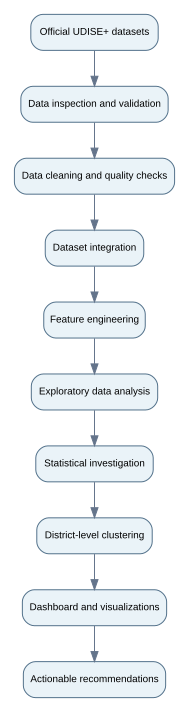

In [1]:

!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display

workflow = Digraph("Project_Workflow", format="png")
workflow.attr(rankdir="TB", bgcolor="white", pad="0.2")
workflow.attr("node", shape="box", style="rounded,filled",
              fontname="Arial", fontsize="10",
              color="#52718A", fillcolor="#EAF3F8")
workflow.attr("edge", color="#64748B")

steps = [
    ("A", "Official UDISE+ datasets"),
    ("B", "Data inspection and validation"),
    ("C", "Data cleaning and quality checks"),
    ("D", "Dataset integration"),
    ("E", "Feature engineering"),
    ("F", "Exploratory data analysis"),
    ("G", "Statistical investigation"),
    ("H", "District-level clustering"),
    ("I", "Dashboard and visualizations"),
    ("J", "Actionable recommendations")
]

for node_id, label in steps:
    workflow.node(node_id, label)

for i in range(len(steps) - 1):
    workflow.edge(steps[i][0], steps[i + 1][0])

display(workflow)


In [2]:

import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Mounted at /content/drive
Libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.1.3


In [3]:

data_path = "/content/drive/MyDrive/India_School_Education_Data"

if os.path.isdir(data_path):
    print("Dataset folder found.")
    print("State folders:", sorted(
        name for name in os.listdir(data_path)
        if os.path.isdir(os.path.join(data_path, name))
    ))
else:
    print("Dataset folder not found. Check the Drive path.")


Dataset folder found.
State folders: ['bihar', 'chhattisgarh', 'haryana', 'jharkhand', 'mp', 'rajasthan', 'up']


In [4]:

csv_files = []

for state in os.listdir(data_path):
    extracted_path = os.path.join(data_path, state, "extracted")

    if not os.path.isdir(extracted_path):
        continue

    for root, dirs, files in os.walk(extracted_path):
        for file in files:
            if file.lower().endswith(".csv"):
                csv_files.append({
                    "State": state,
                    "File": file,
                    "Path": os.path.join(root, file)
                })

csv_index = pd.DataFrame(csv_files)

print("Total CSV files found:", len(csv_files))
display(csv_index[["State", "File"]])


Total CSV files found: 28


,State,File
0,up,09_fac.csv
1,up,09_enr2.csv
2,up,09_tch.csv
3,up,09_prof1.csv
4,mp,23_enr2.csv
5,mp,23_prof1.csv
6,mp,23_fac.csv
7,mp,23_tch.csv
8,haryana,06_enr2.csv
9,haryana,06_tch.csv


In [5]:

summary = []

for item in csv_files:
    try:
        df = pd.read_csv(item["Path"], low_memory=False)

        summary.append({
            "State": item["State"],
            "File": item["File"],
            "Rows": len(df),
            "Columns": len(df.columns),
            "Has pseudocode": "pseudocode" in df.columns,
            "Duplicate pseudocodes": (
                int(df["pseudocode"].duplicated().sum())
                if "pseudocode" in df.columns else None
            ),
            "Missing cells": int(df.isna().sum().sum())
        })

        del df

    except Exception as e:
        print(f"Could not read {item['File']}: {e}")

summary_df = pd.DataFrame(summary)
display(summary_df)


,State,File,Rows,Columns,Has pseudocode,Duplicate pseudocodes,Missing cells
0,up,09_fac.csv,265278,82,True,0,119914
1,up,09_enr2.csv,2491171,42,True,2226206,0
2,up,09_tch.csv,265278,38,True,0,0
3,up,09_prof1.csv,265278,49,True,0,591108
4,mp,23_enr2.csv,1078230,42,True,958536,0
5,mp,23_prof1.csv,119694,49,True,0,261455
6,mp,23_fac.csv,119694,82,True,0,28005
7,mp,23_tch.csv,119694,38,True,0,0
8,haryana,06_enr2.csv,240115,42,True,216636,0
9,haryana,06_tch.csv,23479,38,True,0,0


In [6]:
enrollment_files = [
    item for item in csv_files
    if "enr2" in item["File"].lower()
]

for item in enrollment_files:
    df = pd.read_csv(item["Path"], low_memory=False)

    print(f"\nState: {item['State']} | File: {item['File']}")
    print("Total rows:", len(df))
    print("Unique schools:", df["pseudocode"].nunique())
    print("Repeated school IDs:", df["pseudocode"].duplicated().sum())
    print("Rows per school (first 5):")
    print(df["pseudocode"].value_counts().head())

    del df


State: up | File: 09_enr2.csv
Total rows: 2491171
Unique schools: 264965
Repeated school IDs: 2226206
Rows per school (first 5):
pseudocode
8055542    20
1850504    20
3326129    20
7531763    20
5612453    20
Name: count, dtype: int64

State: mp | File: 23_enr2.csv
Total rows: 1078230
Unique schools: 119694
Repeated school IDs: 958536
Rows per school (first 5):
pseudocode
9270545    20
5201095    20
9535888    20
5229918    20
6946886    20
Name: count, dtype: int64

State: haryana | File: 06_enr2.csv
Total rows: 240115
Unique schools: 23479
Repeated school IDs: 216636
Rows per school (first 5):
pseudocode
3803889    20
9925762    20
3881533    20
5822409    20
4973063    20
Name: count, dtype: int64

State: bihar | File: 10_enr2.csv
Total rows: 972166
Unique schools: 95285
Repeated school IDs: 876881
Rows per school (first 5):
pseudocode
2466470    20
5835556    20
2827523    20
8900964    20
2700859    20
Name: count, dtype: int64

State: rajasthan | File: 08_enr2.csv
Total rows: 1

In [7]:

for item in csv_files:
    if "enr2" not in item["File"].lower():
        continue

    df = pd.read_csv(item["Path"], low_memory=False)

    print(f"\n{'=' * 60}")
    print(f"State: {item['State']} | File: {item['File']}")

    print("\nFirst 25 column names:")
    print(df.columns.tolist()[:25])

    school_id = df["pseudocode"].iloc[0]
    school_rows = df[df["pseudocode"] == school_id]

    print("\nOne school's enrollment records:")
    display(school_rows.head(20))

    print("\nItem group counts:")
    if "item_group" in df.columns:
        print(df["item_group"].value_counts(dropna=False))

    print("\nItem ID counts:")
    if "item_id" in df.columns:
        print(df["item_id"].value_counts(dropna=False).sort_index())

    del df



State: up | File: 09_enr2.csv

First 25 column names:
['pseudocode', 'item_group', 'item_id', 'cpp_b', 'cpp_g', 'cpp_t', 'c1_b', 'c1_g', 'c1_t', 'c2_b', 'c2_g', 'c2_t', 'c3_b', 'c3_g', 'c3_t', 'c4_b', 'c4_g', 'c4_t', 'c5_b', 'c5_g', 'c5_t', 'c6_b', 'c6_g', 'c6_t', 'c7_b']

One school's enrollment records:


,pseudocode,item_group,item_id,cpp_b,cpp_g,cpp_t,c1_b,c1_g,c1_t,c2_b,...,c9_t,c10_b,c10_g,c10_t,c11_b,c11_g,c11_t,c12_b,c12_g,c12_t
0,1000070,8,5,0,0,0,5,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1000070,8,6,0,0,0,3,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1000070,8,7,0,0,0,0,0,0,3,...,0,0,0,0,0,0,0,0,0,0
3,1000070,8,8,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1000070,8,9,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1000070,8,10,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1000070,8,11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,1000070,8,12,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,1000070,8,13,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,1000070,8,14,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Item group counts:
item_group
8    2491171
Name: count, dtype: int64

Item ID counts:
item_id
3      19005
4      62280
5     178759
6     192671
7     200476
8     214990
9     239097
10    243865
11    233137
12    208358
13    174440
14    141090
15    113271
16     85134
17     60883
18     42005
19     30440
20     22297
21     15162
22     13811
Name: count, dtype: int64

State: mp | File: 23_enr2.csv

First 25 column names:
['pseudocode', 'item_group', 'item_id', 'cpp_b', 'cpp_g', 'cpp_t', 'c1_b', 'c1_g', 'c1_t', 'c2_b', 'c2_g', 'c2_t', 'c3_b', 'c3_g', 'c3_t', 'c4_b', 'c4_g', 'c4_t', 'c5_b', 'c5_g', 'c5_t', 'c6_b', 'c6_g', 'c6_t', 'c7_b']

One school's enrollment records:


,pseudocode,item_group,item_id,cpp_b,cpp_g,cpp_t,c1_b,c1_g,c1_t,c2_b,...,c9_t,c10_b,c10_g,c10_t,c11_b,c11_g,c11_t,c12_b,c12_g,c12_t
0,1000089,8,3,6,3,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1000089,8,4,6,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1000089,8,5,4,2,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1000089,8,6,0,3,0,3,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1000089,8,7,0,0,0,0,1,0,2,...,0,0,0,0,0,0,0,0,0,0
5,1000089,8,8,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1000089,8,9,0,0,0,1,0,0,2,...,0,0,0,0,0,0,0,0,0,0
7,1000089,8,10,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,1000089,8,11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,1000089,8,12,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Item group counts:
item_group
8    1078230
Name: count, dtype: int64

Item ID counts:
item_id
3      24788
4      35765
5      93974
6     101789
7     103045
8     104037
9     109773
10    102455
11     89577
12     79242
13     67721
14     53385
15     37903
16     28109
17     19056
18     12684
19      7952
20      4106
21      1638
22      1231
Name: count, dtype: int64

State: haryana | File: 06_enr2.csv

First 25 column names:
['pseudocode', 'item_group', 'item_id', 'cpp_b', 'cpp_g', 'cpp_t', 'c1_b', 'c1_g', 'c1_t', 'c2_b', 'c2_g', 'c2_t', 'c3_b', 'c3_g', 'c3_t', 'c4_b', 'c4_g', 'c4_t', 'c5_b', 'c5_g', 'c5_t', 'c6_b', 'c6_g', 'c6_t', 'c7_b']

One school's enrollment records:


...


Item group counts:
item_group
8    1084857
Name: count, dtype: int64

Item ID counts:
item_id
3      17177
4      44751
5      88667
6      99095
7     100905
8     100822
9      99941
10     92671
11     83126
12     74960
13     67784
14     56572
15     44743
16     36868
17     30427
18     23448
19     14172
20      5769
21      1837
22      1122
Name: count, dtype: int64

State: chhattisgarh | File: 22_enr2.csv

First 25 column names:
['pseudocode', 'item_group', 'item_id', 'cpp_b', 'cpp_g', 'cpp_t', 'c1_b', 'c1_g', 'c1_t', 'c2_b', 'c2_g', 'c2_t', 'c3_b', 'c3_g', 'c3_t', 'c4_b', 'c4_g', 'c4_t', 'c5_b', 'c5_g', 'c5_t', 'c6_b', 'c6_g', 'c6_t', 'c7_b']

One school's enrollment records:


,pseudocode,item_group,item_id,cpp_b,cpp_g,cpp_t,c1_b,c1_g,c1_t,c2_b,...,c9_t,c10_b,c10_g,c10_t,c11_b,c11_g,c11_t,c12_b,c12_g,c12_t
0,1000021,8,5,0,0,0,6,4,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1000021,8,6,0,0,0,1,2,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1000021,8,7,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1000021,8,8,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
4,1000021,8,9,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1000021,8,10,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1000021,8,11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,1000021,8,13,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Item group counts:
item_group
8    421820
Name: count, dtype: int64

Item ID counts:
item_id
3      7094
4     16164
5     36089
6     38178
7     38358
8     38485
9     43735
10    48575
11    36728
12    30520
13    26936
14    21302
15    12745
16     8805
17     6709
18     5253
19     3312
20     1558
21      630
22      644
Name: count, dtype: int64

State: jharkhand | File: 20_enr2.csv

First 25 column names:
['pseudocode', 'item_group', 'item_id', 'cpp_b', 'cpp_g', 'cpp_t', 'c1_b', 'c1_g', 'c1_t', 'c2_b', 'c2_g', 'c2_t', 'c3_b', 'c3_g', 'c3_t', 'c4_b', 'c4_g', 'c4_t', 'c5_b', 'c5_g', 'c5_t', 'c6_b', 'c6_g', 'c6_t', 'c7_b']

One school's enrollment records:


,pseudocode,item_group,item_id,cpp_b,cpp_g,cpp_t,c1_b,c1_g,c1_t,c2_b,...,c9_t,c10_b,c10_g,c10_t,c11_b,c11_g,c11_t,c12_b,c12_g,c12_t
0,1000233,8,5,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1000233,8,6,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1000233,8,7,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
3,1000233,8,8,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1000233,8,9,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,1000233,8,10,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,1000233,8,11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,1000233,8,12,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Item group counts:
item_group
8    433493
Name: count, dtype: int64

Item ID counts:
item_id
3      5093
4     18187
5     38011
6     40774
7     41155
8     41316
9     41762
10    41035
11    36258
12    29970
13    25313
14    20602
15    16721
16    13279
17     8192
18     5366
19     3997
20     2881
21     1739
22     1842
Name: count, dtype: int64


In [8]:

import pandas as pd

for item in csv_files:
    if item["File"].endswith("_enr2.csv"):
        df = pd.read_csv(item["Path"], low_memory=False)

        print("=" * 70)
        print("State:", item["State"])
        print("File:", item["File"])
        print("Shape:", df.shape)
        print("Unique schools:", df["pseudocode"].nunique())
        print("Unique item groups:", df["item_group"].unique())
        print("Unique item IDs:", sorted(df["item_id"].unique()))

        print("\nSample records:")
        display(df.head(5))

        print("\nRows per school:")
        print(df.groupby("pseudocode").size().describe())

        print("\nMissing values by column:")
        display(df.isna().sum().to_frame("Missing values"))

        del df


State: up
File: 09_enr2.csv
Shape: (2491171, 42)
Unique schools: 264965
Unique item groups: [8]
Unique item IDs: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]

Sample records:


,pseudocode,item_group,item_id,cpp_b,cpp_g,cpp_t,c1_b,c1_g,c1_t,c2_b,...,c9_t,c10_b,c10_g,c10_t,c11_b,c11_g,c11_t,c12_b,c12_g,c12_t
0,1000070,8,5,0,0,0,5,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1000070,8,6,0,0,0,3,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1000070,8,7,0,0,0,0,0,0,3,...,0,0,0,0,0,0,0,0,0,0
3,1000070,8,8,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1000070,8,9,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Rows per school:
count    264965.000000
mean          9.401887
std           3.033644
min           1.000000
25%           7.000000
50%           9.000000
75%          11.000000
max          20.000000
dtype: float64

Missing values by column:


,Missing values
pseudocode,0
item_group,0
item_id,0
cpp_b,0
cpp_g,0
cpp_t,0
c1_b,0
c1_g,0
c1_t,0
c2_b,0


State: mp
File: 23_enr2.csv
Shape: (1078230, 42)
Unique schools: 119694
Unique item groups: [8]
Unique item IDs: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]

Sample records:


...

,Missing values
pseudocode,0
item_group,0
item_id,0
cpp_b,0
cpp_g,0
cpp_t,0
c1_b,0
c1_g,0
c1_t,0
c2_b,0


State: jharkhand
File: 20_enr2.csv
Shape: (433493, 42)
Unique schools: 44253
Unique item groups: [8]
Unique item IDs: [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22)]

Sample records:


,pseudocode,item_group,item_id,cpp_b,cpp_g,cpp_t,c1_b,c1_g,c1_t,c2_b,...,c9_t,c10_b,c10_g,c10_t,c11_b,c11_g,c11_t,c12_b,c12_g,c12_t
0,1000233,8,5,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1000233,8,6,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
2,1000233,8,7,0,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,0
3,1000233,8,8,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1000233,8,9,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Rows per school:
count    44253.000000
mean         9.795788
std          3.098300
min          1.000000
25%          7.000000
50%          9.000000
75%         12.000000
max         20.000000
dtype: float64

Missing values by column:


,Missing values
pseudocode,0
item_group,0
item_id,0
cpp_b,0
cpp_g,0
cpp_t,0
c1_b,0
c1_g,0
c1_t,0
c2_b,0


In [13]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_BIHAR_2025-26.zip to enrolment_data_2_BIHAR_2025-26.zip
Saving facility_data_BIHAR_2025-26.zip to facility_data_BIHAR_2025-26.zip
Saving profile_data_1_BIHAR_2025-26.zip to profile_data_1_BIHAR_2025-26.zip
Saving teacher_data_BIHAR_2025-26.zip to teacher_data_BIHAR_2025-26.zip
Loaded: enrolment_data_2_BIHAR_2025-26.zip
Shape: (972166, 42)


In [15]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_CHHATTISGARH_2025-26.zip to enrolment_data_2_CHHATTISGARH_2025-26.zip
Saving facility_data_CHHATTISGARH_2025-26.zip to facility_data_CHHATTISGARH_2025-26.zip
Saving profile_data_1_CHHATTISGARH_2025-26.zip to profile_data_1_CHHATTISGARH_2025-26.zip
Saving teacher_data_CHHATTISGARH_2025-26.zip to teacher_data_CHHATTISGARH_2025-26.zip
Loaded: enrolment_data_2_CHHATTISGARH_2025-26.zip
Shape: (421820, 42)


In [16]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_HARYANA_2025-26.zip to enrolment_data_2_HARYANA_2025-26.zip
Saving facility_data_HARYANA_2025-26.zip to facility_data_HARYANA_2025-26.zip
Saving profile_data_1_HARYANA_2025-26.zip to profile_data_1_HARYANA_2025-26.zip
Saving teacher_data_HARYANA_2025-26.zip to teacher_data_HARYANA_2025-26.zip
Loaded: enrolment_data_2_HARYANA_2025-26.zip
Shape: (240115, 42)


In [17]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_JHARKHAND_2025-26.zip to enrolment_data_2_JHARKHAND_2025-26.zip
Saving facility_data_JHARKHAND_2025-26.zip to facility_data_JHARKHAND_2025-26.zip
Saving profile_data_1_JHARKHAND_2025-26.zip to profile_data_1_JHARKHAND_2025-26.zip
Saving teacher_data_JHARKHAND_2025-26.zip to teacher_data_JHARKHAND_2025-26.zip
Loaded: enrolment_data_2_JHARKHAND_2025-26.zip
Shape: (433493, 42)


In [18]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_MADHYA PRADESH_2025-26.zip to enrolment_data_2_MADHYA PRADESH_2025-26.zip
Saving facility_data_MADHYA PRADESH_2025-26.zip to facility_data_MADHYA PRADESH_2025-26.zip
Saving profile_data_1_MADHYA PRADESH_2025-26.zip to profile_data_1_MADHYA PRADESH_2025-26.zip
Saving teacher_data_MADHYA PRADESH_2025-26.zip to teacher_data_MADHYA PRADESH_2025-26.zip
Loaded: enrolment_data_2_MADHYA PRADESH_2025-26.zip
Shape: (1078230, 42)


In [19]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_RAJASTHAN_2025-26.zip to enrolment_data_2_RAJASTHAN_2025-26.zip
Saving facility_data_RAJASTHAN_2025-26.zip to facility_data_RAJASTHAN_2025-26.zip
Saving profile_data_1_RAJASTHAN_2025-26.zip to profile_data_1_RAJASTHAN_2025-26.zip
Saving teacher_data_RAJASTHAN_2025-26.zip to teacher_data_RAJASTHAN_2025-26.zip
Loaded: enrolment_data_2_RAJASTHAN_2025-26.zip
Shape: (1084857, 42)


In [20]:

from google.colab import files
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Shape:", df.shape)


Saving enrolment_data_2_UTTAR PRADESH_2025-26.zip to enrolment_data_2_UTTAR PRADESH_2025-26.zip
Saving facility_data_UTTAR PRADESH_2025-26.zip to facility_data_UTTAR PRADESH_2025-26.zip
Saving profile_data_1_UTTAR PRADESH_2025-26.zip to profile_data_1_UTTAR PRADESH_2025-26.zip
Saving teacher_data_UTTAR PRADESH_2025-26.zip to teacher_data_UTTAR PRADESH_2025-26.zip
Loaded: enrolment_data_2_UTTAR PRADESH_2025-26.zip
Shape: (2491171, 42)


In [22]:
import zipfile
import os

for file in os.listdir():
    if file.endswith(".zip"):
        folder = file.replace(".zip", "")
        os.makedirs(folder, exist_ok=True)

        with zipfile.ZipFile(file, "r") as zip_ref:
            zip_ref.extractall(folder)

        print("Extracted:", file)

Extracted: facility_data_JHARKHAND_2025-26.zip
Extracted: teacher_data_JHARKHAND_2025-26.zip
Extracted: facility_data_RAJASTHAN_2025-26.zip
Extracted: facility_data_CHHATTISGARH_2025-26.zip
Extracted: teacher_data_BIHAR_2025-26.zip
Extracted: teacher_data_CHHATTISGARH_2025-26.zip
Extracted: facility_data_BIHAR_2025-26.zip
Extracted: profile_data_1_MADHYA PRADESH_2025-26.zip
Extracted: profile_data_1_HARYANA_2025-26.zip
Extracted: profile_data_1_BIHAR_2025-26.zip
Extracted: teacher_data_RAJASTHAN_2025-26.zip
Extracted: enrolment_data_2_HARYANA_2025-26.zip
Extracted: enrolment_data_2_MADHYA PRADESH_2025-26.zip
Extracted: facility_data_MADHYA PRADESH_2025-26.zip
Extracted: teacher_data_HARYANA_2025-26.zip
Extracted: profile_data_1_UTTAR PRADESH_2025-26.zip
Extracted: enrolment_data_2_UTTAR PRADESH_2025-26.zip
Extracted: enrolment_data_2_RAJASTHAN_2025-26.zip
Extracted: facility_data_UTTAR PRADESH_2025-26.zip
Extracted: enrolment_data_2_CHHATTISGARH_2025-26.zip
Extracted: profile_data_1_RA

In [23]:

print("Extracted folders:")
for folder in os.listdir():
    if os.path.isdir(folder):
        print(folder)

Extracted folders:
.config
profile_data_1_JHARKHAND_2025-26
teacher_data_JHARKHAND_2025-26
teacher_data_RAJASTHAN_2025-26
teacher_data_BIHAR_2025-26
enrolment_data_2_BIHAR_2025-26
enrolment_data_2_JHARKHAND_2025-26
teacher_data_MADHYA PRADESH_2025-26
enrolment_data_2_HARYANA_2025-26
teacher_data_UTTAR PRADESH_2025-26
enrolment_data_2_UTTAR PRADESH_2025-26
profile_data_1_HARYANA_2025-26
profile_data_1_RAJASTHAN_2025-26
enrolment_data_2_CHHATTISGARH_2025-26
profile_data_1_BIHAR_2025-26
facility_data_MADHYA PRADESH_2025-26
facility_data_UTTAR PRADESH_2025-26
enrolment_data_2_MADHYA PRADESH_2025-26
profile_data_1_UTTAR PRADESH_2025-26
facility_data_CHHATTISGARH_2025-26
drive
facility_data_HARYANA_2025-26
profile_data_1_CHHATTISGARH_2025-26
teacher_data_CHHATTISGARH_2025-26
teacher_data_HARYANA_2025-26
enrolment_data_2_RAJASTHAN_2025-26
facility_data_BIHAR_2025-26
facility_data_RAJASTHAN_2025-26
profile_data_1_MADHYA PRADESH_2025-26
facility_data_JHARKHAND_2025-26
sample_data


In [24]:
for folder in os.listdir():
    if os.path.isdir(folder):
        print(f"\n{folder}:")
        for root, dirs, files in os.walk(folder):
            for file in files:
                if file.endswith(".csv"):
                    print(os.path.join(root, file))


.config:

profile_data_1_JHARKHAND_2025-26:
profile_data_1_JHARKHAND_2025-26/20_prof1.csv

teacher_data_JHARKHAND_2025-26:
teacher_data_JHARKHAND_2025-26/20_tch.csv

teacher_data_RAJASTHAN_2025-26:
teacher_data_RAJASTHAN_2025-26/08_tch.csv

teacher_data_BIHAR_2025-26:
teacher_data_BIHAR_2025-26/10_tch.csv

enrolment_data_2_BIHAR_2025-26:
enrolment_data_2_BIHAR_2025-26/10_enr2.csv

enrolment_data_2_JHARKHAND_2025-26:
enrolment_data_2_JHARKHAND_2025-26/20_enr2.csv

teacher_data_MADHYA PRADESH_2025-26:
teacher_data_MADHYA PRADESH_2025-26/23_tch.csv

enrolment_data_2_HARYANA_2025-26:
enrolment_data_2_HARYANA_2025-26/06_enr2.csv

teacher_data_UTTAR PRADESH_2025-26:
teacher_data_UTTAR PRADESH_2025-26/09_tch.csv

enrolment_data_2_UTTAR PRADESH_2025-26:
enrolment_data_2_UTTAR PRADESH_2025-26/09_enr2.csv

profile_data_1_HARYANA_2025-26:
profile_data_1_HARYANA_2025-26/06_prof1.csv

profile_data_1_RAJASTHAN_2025-26:
profile_data_1_RAJASTHAN_2025-26/08_prof1.csv

enrolment_data_2_CHHATTISGARH_202

In [25]:

base_path = "/content/drive/MyDrive/India_School_Education_Data"

inventory = []

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith(".csv"):
            path = os.path.join(root, file)

            try:
                data = pd.read_csv(path, nrows=5)

                with open(path, encoding="utf-8", errors="replace") as f:
                    total_rows = sum(1 for _ in f) - 1

                inventory.append({
                    "File": file,
                    "Folder": os.path.relpath(root, base_path),
                    "Rows": total_rows,
                    "Columns": len(data.columns),
                    "Column Names": ", ".join(data.columns.astype(str))
                })

            except Exception as e:
                print(f"Could not read {path}: {e}")

inventory_df = pd.DataFrame(inventory)

print("Total CSV files found:", len(inventory_df))
display(inventory_df)


Total CSV files found: 28


,File,Folder,Rows,Columns,Column Names
0,09_fac.csv,up/extracted,265278,82,"pseudocode, building_status, no_building_block..."
1,09_enr2.csv,up/extracted,2491171,42,"pseudocode, item_group, item_id, cpp_b, cpp_g,..."
2,09_tch.csv,up/extracted,265278,38,"pseudocode, total_tch, male, female, transgend..."
3,09_prof1.csv,up/extracted,265278,49,"pseudocode, state, district, block, rural_urba..."
4,23_enr2.csv,mp/extracted,1078230,42,"pseudocode, item_group, item_id, cpp_b, cpp_g,..."
5,23_prof1.csv,mp/extracted,119694,49,"pseudocode, state, district, block, rural_urba..."
6,23_fac.csv,mp/extracted,119694,82,"pseudocode, building_status, no_building_block..."
7,23_tch.csv,mp/extracted,119694,38,"pseudocode, total_tch, male, female, transgend..."
8,06_enr2.csv,haryana/extracted,240115,42,"pseudocode, item_group, item_id, cpp_b, cpp_g,..."
9,06_tch.csv,haryana/extracted,23479,38,"pseudocode, total_tch, male, female, transgend..."


In [26]:

# Check the school identifiers in each dataset

for state in ["haryana", "bihar", "rajasthan",
              "chhattisgarh", "jharkhand", "mp", "up"]:

    print(f"\n{'=' * 50}")
    print("STATE:", state.upper())

    state_folder = os.path.join(base_path, state, "extracted")

    if not os.path.exists(state_folder):
        print("Folder not found:", state_folder)
        continue

    for file in sorted(os.listdir(state_folder)):
        if file.endswith(".csv"):
            path = os.path.join(state_folder, file)
            temp = pd.read_csv(path, usecols=["pseudocode"])

            print(
                file,
                "| Rows:", len(temp),
                "| Unique school IDs:", temp["pseudocode"].nunique()
            )



STATE: HARYANA
06_enr2.csv | Rows: 240115 | Unique school IDs: 23479
06_fac.csv | Rows: 23479 | Unique school IDs: 23479
06_prof1.csv | Rows: 23479 | Unique school IDs: 23479
06_tch.csv | Rows: 23479 | Unique school IDs: 23479

STATE: BIHAR
10_enr2.csv | Rows: 972166 | Unique school IDs: 95285
10_fac.csv | Rows: 95285 | Unique school IDs: 95285
10_prof1.csv | Rows: 95285 | Unique school IDs: 95285
10_tch.csv | Rows: 95285 | Unique school IDs: 95285

STATE: RAJASTHAN
08_enr2.csv | Rows: 1084857 | Unique school IDs: 106305
08_fac.csv | Rows: 106445 | Unique school IDs: 106445
08_prof1.csv | Rows: 106445 | Unique school IDs: 106445
08_tch.csv | Rows: 106445 | Unique school IDs: 106445

STATE: CHHATTISGARH
22_enr2.csv | Rows: 421820 | Unique school IDs: 56887
22_fac.csv | Rows: 57036 | Unique school IDs: 57036
22_prof1.csv | Rows: 57036 | Unique school IDs: 57036
22_tch.csv | Rows: 57036 | Unique school IDs: 57036

STATE: JHARKHAND
20_enr2.csv | Rows: 433493 | Unique school IDs: 44253
20_

In [27]:
# Verify exact ID matching
for state, prefix in [
    ("haryana", "06"),
    ("bihar", "10"),
    ("rajasthan", "08"),
    ("chhattisgarh", "22"),
    ("jharkhand", "20"),
    ("mp", "23"),
    ("up", "09")
]:
    folder = os.path.join(base_path, state, "extracted")

    profile = pd.read_csv(
        os.path.join(folder, f"{prefix}_prof1.csv"),
        usecols=["pseudocode"]
    )
    facility = pd.read_csv(
        os.path.join(folder, f"{prefix}_fac.csv"),
        usecols=["pseudocode"]
    )
    teacher = pd.read_csv(
        os.path.join(folder, f"{prefix}_tch.csv"),
        usecols=["pseudocode"]
    )
    enrollment = pd.read_csv(
        os.path.join(folder, f"{prefix}_enr2.csv"),
        usecols=["pseudocode"]
    )

    profile_ids = set(profile["pseudocode"])
    facility_ids = set(facility["pseudocode"])
    teacher_ids = set(teacher["pseudocode"])
    enrollment_ids = set(enrollment["pseudocode"])

    print(f"\n{state.upper()}")
    print("Profile = Facility:", profile_ids == facility_ids)
    print("Profile = Teacher:", profile_ids == teacher_ids)
    print("Profile = Enrollment:", profile_ids == enrollment_ids)
    print("Duplicate profile IDs:", profile["pseudocode"].duplicated().sum())
    print("Duplicate facility IDs:", facility["pseudocode"].duplicated().sum())
    print("Duplicate teacher IDs:", teacher["pseudocode"].duplicated().sum())



HARYANA
Profile = Facility: True
Profile = Teacher: True
Profile = Enrollment: True
Duplicate profile IDs: 0
Duplicate facility IDs: 0
Duplicate teacher IDs: 0

BIHAR
Profile = Facility: True
Profile = Teacher: True
Profile = Enrollment: True
Duplicate profile IDs: 0
Duplicate facility IDs: 0
Duplicate teacher IDs: 0

RAJASTHAN
Profile = Facility: True
Profile = Teacher: True
Profile = Enrollment: False
Duplicate profile IDs: 0
Duplicate facility IDs: 0
Duplicate teacher IDs: 0

CHHATTISGARH
Profile = Facility: True
Profile = Teacher: True
Profile = Enrollment: False
Duplicate profile IDs: 0
Duplicate facility IDs: 0
Duplicate teacher IDs: 0

JHARKHAND
Profile = Facility: True
Profile = Teacher: True
Profile = Enrollment: False
Duplicate profile IDs: 0
Duplicate facility IDs: 0
Duplicate teacher IDs: 0

MP
Profile = Facility: True
Profile = Teacher: True
Profile = Enrollment: True
Duplicate profile IDs: 0
Duplicate facility IDs: 0
Duplicate teacher IDs: 0

UP
Profile = Facility: True


In [28]:
# missing school IDs#
for state, prefix in [
    ("rajasthan", "08"),
    ("chhattisgarh", "22"),
    ("jharkhand", "20"),
    ("up", "09")
]:
    folder = os.path.join(base_path, state, "extracted")

    profile_ids = set(pd.read_csv(
        os.path.join(folder, f"{prefix}_prof1.csv"),
        usecols=["pseudocode"]
    )["pseudocode"])

    enrollment_ids = set(pd.read_csv(
        os.path.join(folder, f"{prefix}_enr2.csv"),
        usecols=["pseudocode"]
    )["pseudocode"])

    print(f"\n{state.upper()}")
    print("Schools in profile:", len(profile_ids))
    print("Schools in enrollment:", len(enrollment_ids))
    print("Missing from enrollment:", len(profile_ids - enrollment_ids))
    print("Only in enrollment:", len(enrollment_ids - profile_ids))
    print("Sample IDs missing from enrollment:",
          list(profile_ids - enrollment_ids)[:10])



RAJASTHAN
Schools in profile: 106445
Schools in enrollment: 106305
Missing from enrollment: 140
Only in enrollment: 0
Sample IDs missing from enrollment: [1341455, 1532946, 1022490, 4356124, 3923484, 3099167, 3031075, 7329833, 1256490, 7142955]

CHHATTISGARH
Schools in profile: 57036
Schools in enrollment: 56887
Missing from enrollment: 149
Only in enrollment: 0
Sample IDs missing from enrollment: [3445250, 7910918, 4713993, 6001676, 9017869, 8690706, 2938392, 1838620, 3039772, 1690653]

JHARKHAND
Schools in profile: 44378
Schools in enrollment: 44253
Missing from enrollment: 125
Only in enrollment: 0
Sample IDs missing from enrollment: [3913221, 5883415, 3074076, 2722333, 5452319, 9618465, 2836006, 5868582, 5701673, 8106028]

UP
Schools in profile: 265278
Schools in enrollment: 264965
Missing from enrollment: 313
Only in enrollment: 0
Sample IDs missing from enrollment: [7841797, 2160646, 9863174, 7309320, 2902029, 2488333, 6307873, 9345062, 8910889, 4915246]


In [29]:
# MISSING SCHOOLS


for state, prefix in [
    ("rajasthan", "08"),
    ("chhattisgarh", "22"),
    ("jharkhand", "20"),
    ("up", "09")
]:
    folder = os.path.join(base_path, state, "extracted")

    profile = pd.read_csv(
        os.path.join(folder, f"{prefix}_prof1.csv")
    )
    enrollment = pd.read_csv(
        os.path.join(folder, f"{prefix}_enr2.csv"),
        usecols=["pseudocode"]
    )

    missing_ids = set(profile["pseudocode"]) - set(enrollment["pseudocode"])
    missing_profile = profile[profile["pseudocode"].isin(missing_ids)]

    print(f"\n{state.upper()}")
    print("Missing school IDs:", len(missing_ids))

    available_columns = [
        col for col in ["pseudocode", "state", "district", "block",
                        "rural_urban", "school_category"]
        if col in missing_profile.columns
    ]

    print(missing_profile[available_columns].head(10).to_string(index=False))



RAJASTHAN
Missing school IDs: 140
 pseudocode     state        district      block  rural_urban  school_category
    2929590 RAJASTHAN          JALORE    BHINMAL            1                1
    7459649 RAJASTHAN       JHUNJHUNU     KHETRI            1                2
    3031075 RAJASTHAN         BALOTRA     SIWANA            1                1
    1296685 RAJASTHAN KOTPUTLI-BEHROR     BEHROR            1                1
    6832545 RAJASTHAN           BARAN KISHANGANJ            1                1
    3860861 RAJASTHAN         BALOTRA    BALOTRA            1                1
    4615818 RAJASTHAN       JHUNJHUNU     KHETRI            1                1
    4503184 RAJASTHAN          JALORE   SANCHORE            1                1
    4231127 RAJASTHAN           AJMER   AJMER(U)            2                2
    9987876 RAJASTHAN       JHUNJHUNU     PILANI            1                1

CHHATTISGARH
Missing school IDs: 149
 pseudocode        state         district     block  rural

In [30]:

# Check whether missing school IDs exist in the other datasets

for state in ["rajasthan", "chhattisgarh", "jharkhand", "up"]:
    print(f"\n{'='*20} {state.upper()} {'='*20}")

    folder = os.path.join(base_path, state, "extracted")

    profile_files = [
        f for f in os.listdir(folder)
        if f.endswith("_prof1.csv")
    ]

    if not profile_files:
        print("Profile file not found")
        continue

    profile = pd.read_csv(
        os.path.join(folder, profile_files[0]),
        dtype={"pseudocode": str}
    )

    print("Profile rows:", len(profile))
    print("Unique school IDs:", profile["pseudocode"].nunique())
    print("Missing IDs:", profile["pseudocode"].isna().sum())
    print("Duplicate IDs:", profile["pseudocode"].duplicated().sum())



==================== RAJASTHAN ====================
Profile rows: 106445
Unique school IDs: 106445
Missing IDs: 0
Duplicate IDs: 0

==================== CHHATTISGARH ====================
Profile rows: 57036
Unique school IDs: 57036
Missing IDs: 0
Duplicate IDs: 0

==================== JHARKHAND ====================
Profile rows: 44378
Unique school IDs: 44378
Missing IDs: 0
Duplicate IDs: 0

==================== UP ====================
Profile rows: 265278
Unique school IDs: 265278
Missing IDs: 0
Duplicate IDs: 0


In [32]:

from pathlib import Path

base_path = Path("/content/drive/MyDrive/India_School_Education_Data")

for state, code in [
    ("RAJASTHAN", "08"),
    ("CHHATTISGARH", "22"),
    ("JHARKHAND", "20"),
    ("UP", "09")
]:
    profile_files = list(base_path.rglob(f"{code}_prof1.csv"))
    enrollment_files = list(base_path.rglob(f"{code}_enr2.csv"))

    if not profile_files or not enrollment_files:
        print(f"{state}: Profile or enrollment CSV not found.")
        continue

    profile = pd.read_csv(profile_files[0], dtype={"pseudocode": str})
    enrollment = pd.read_csv(enrollment_files[0], dtype={"pseudocode": str})

    profile_ids = set(profile["pseudocode"].str.strip())
    enrollment_ids = set(enrollment["pseudocode"].str.strip())

    missing_ids = profile_ids - enrollment_ids

    print(f"\n{state}")
    print("Profile IDs:", len(profile_ids))
    print("Enrollment IDs:", len(enrollment_ids))
    print("Missing from enrollment:", len(missing_ids))
    print("Sample missing IDs:", list(missing_ids)[:5])



RAJASTHAN
Profile IDs: 106445
Enrollment IDs: 106305
Missing from enrollment: 140
Sample missing IDs: ['4125097', '1824895', '5790977', '5886187', '5243239']

CHHATTISGARH
Profile IDs: 57036
Enrollment IDs: 56887
Missing from enrollment: 149
Sample missing IDs: ['6910525', '7628941', '5375142', '2256138', '4297375']

JHARKHAND
Profile IDs: 44378
Enrollment IDs: 44253
Missing from enrollment: 125
Sample missing IDs: ['1761097', '2722333', '5145535', '7523091', '5128555']

UP
Profile IDs: 265278
Enrollment IDs: 264965
Missing from enrollment: 313
Sample missing IDs: ['2587298', '1389666', '3548449', '6891977', '3589808']


In [33]:

for state, code in [
    ("RAJASTHAN", "08"),
    ("CHHATTISGARH", "22"),
    ("JHARKHAND", "20"),
    ("UP", "09")
]:
    profile_files = list(base_path.rglob(f"{code}_prof1.csv"))
    enrollment_files = list(base_path.rglob(f"{code}_enr2.csv"))

    if not profile_files or not enrollment_files:
        print(f"{state}: Files not found")
        continue

    profile = pd.read_csv(profile_files[0], dtype={"pseudocode": str})
    enrollment = pd.read_csv(enrollment_files[0], dtype={"pseudocode": str})

    profile["pseudocode"] = profile["pseudocode"].str.strip()
    enrollment["pseudocode"] = enrollment["pseudocode"].str.strip()

    missing_ids = set(profile["pseudocode"]) - set(enrollment["pseudocode"])
    missing_rows = profile[profile["pseudocode"].isin(missing_ids)]

    print(f"\n{state}: First 5 unmatched profile records")
    display(missing_rows.head())



RAJASTHAN: First 5 unmatched profile records


,pseudocode,state,district,block,rural_urban,lgd_urban_local_body_name,lgd_ward_name,lgd_vill_name,lgd_vill_panchayat_name,lgd_block_name,...,rte_25p_admission_yn,estd_year,certified_fit_india_yn,is_nsqf,prevoc_yn,stc_yn,smdc_pta_yn,smdc_pta_meeting,remedial_tch_enrol,learner_holistic_rptcard_yn
342,2929590,RAJASTHAN,JALORE,BHINMAL,1,NaN,NaN,Joojani,Junjani,Bhinmal,...,9,1999,1,2,9,2,1,0,0,1
1312,7459649,RAJASTHAN,JHUNJHUNU,KHETRI,1,NaN,NaN,Doodhwa Nangliya,Doodhwa Nangliya,Khetri,...,9,1996,2,2,2,2,1,4,0,1
1607,3031075,RAJASTHAN,BALOTRA,SIWANA,1,NaN,NaN,Mithora,Mithora,Siwana,...,9,2002,1,2,9,2,1,0,0,1
2574,1296685,RAJASTHAN,KOTPUTLI-BEHROR,BEHROR,1,NaN,NaN,Balpura,Bhagwari Khurd,Behror,...,9,1983,1,2,9,2,1,5,0,1
3015,6832545,RAJASTHAN,BARAN,KISHANGANJ,1,NaN,NaN,Khandela,Khandela,Kishanganj,...,9,2009,1,2,9,2,1,0,0,1



CHHATTISGARH: First 5 unmatched profile records


,pseudocode,state,district,block,rural_urban,lgd_urban_local_body_name,lgd_ward_name,lgd_vill_name,lgd_vill_panchayat_name,lgd_block_name,...,rte_25p_admission_yn,estd_year,certified_fit_india_yn,is_nsqf,prevoc_yn,stc_yn,smdc_pta_yn,smdc_pta_meeting,remedial_tch_enrol,learner_holistic_rptcard_yn
621,4490466,CHHATTISGARH,SUKMA,KONTA,1,NaN,NaN,Chintagupha,Chintagupha,Konta,...,9,1995,1,2,2,2,1,3,0,1
622,7190360,CHHATTISGARH,MAHASAMUND,BAGBAHARA,1,NaN,NaN,Tusda,Tusda,Bagbahara,...,9,1997,2,2,9,2,1,2,0,1
742,2951730,CHHATTISGARH,JANJGIR - CHAMPA,PAMGARH,1,NaN,NaN,Konar,Konar,Pamgarh,...,9,1997,1,2,9,2,1,4,8,1
881,1475055,CHHATTISGARH,SURAJPUR,PRATAPPUR,1,NaN,NaN,Jagannathpur,Jagarnathpur,Pratappur,...,9,1981,1,2,9,2,1,0,2,1
1173,9494268,CHHATTISGARH,JASHPUR,KUNKURI,2,Kunkuri-Town Panchayat,DR.AMBEDKAR WARD,NaN,NaN,NaN,...,9,2006,1,2,9,2,1,2,0,1



JHARKHAND: First 5 unmatched profile records


,pseudocode,state,district,block,rural_urban,lgd_urban_local_body_name,lgd_ward_name,lgd_vill_name,lgd_vill_panchayat_name,lgd_block_name,...,rte_25p_admission_yn,estd_year,certified_fit_india_yn,is_nsqf,prevoc_yn,stc_yn,smdc_pta_yn,smdc_pta_meeting,remedial_tch_enrol,learner_holistic_rptcard_yn
1,9214686,JHARKHAND,RANCHI,ANGARA,1,NaN,NaN,Angara,Angara,Angara,...,9,2006,2,2,9,2,2,0,0,2
364,2622655,JHARKHAND,GUMLA,GHAGHRA,1,NaN,NaN,Icha,Chundari,Ghaghra,...,9,2002,2,2,9,2,2,0,0,2
885,3913221,JHARKHAND,Hazaribagh,BARKAGAON,1,NaN,NaN,Sinduari,Sinduwari,Barkagaon,...,9,2002,2,2,9,1,1,9,0,2
960,1316717,JHARKHAND,GUMLA,KAMDARA,1,NaN,NaN,Bamhani,Ramtolya,Kamdara,...,9,2002,1,2,9,2,1,3,0,2
1007,1983314,JHARKHAND,KHUNTI,MURHU,1,NaN,NaN,Kudapurti,Kurapurti,Murhu,...,9,2002,2,2,9,2,2,0,0,2



UP: First 5 unmatched profile records


,pseudocode,state,district,block,rural_urban,lgd_urban_local_body_name,lgd_ward_name,lgd_vill_name,lgd_vill_panchayat_name,lgd_block_name,...,rte_25p_admission_yn,estd_year,certified_fit_india_yn,is_nsqf,prevoc_yn,stc_yn,smdc_pta_yn,smdc_pta_meeting,remedial_tch_enrol,learner_holistic_rptcard_yn
2440,2750731,UTTAR PRADESH,GORAKHPUR,NAGAR KSHETRA,2,Gorakhpur-Municipal Corporations,Gorakhpur (M Corp.) - Ward No.22,NaN,NaN,NaN,...,9,1939,2,2,9,2,2,0,0,2
3066,5122447,UTTAR PRADESH,AGRA,BAH,1,NaN,NaN,Kanera,Rajpura,Bah,...,9,2014,1,2,2,2,2,0,0,1
3871,3621133,UTTAR PRADESH,BUDAUN,KAKRALA CITY,2,Kakrala-Municipality,Kakrala (MB) - Ward No.18,NaN,NaN,NaN,...,9,1968,2,2,9,2,1,4,0,1
4045,3826024,UTTAR PRADESH,BUDAUN,USAWAN,1,NaN,NaN,Khera Jalalpur Kham,Kheda Jalalpur Kham,Usawan,...,9,1999,2,2,9,2,1,10,0,2
4506,3737385,UTTAR PRADESH,BUDAUN,SAHASWAN,1,NaN,NaN,Kakrala,Kyawali,Sahaswan,...,9,2000,2,2,2,2,1,4,7,1


In [34]:

for state, code in [
    ("RAJASTHAN", "08"),
    ("CHHATTISGARH", "22"),
    ("JHARKHAND", "20"),
    ("UP", "09")
]:
    profile_files = list(base_path.rglob(f"{code}_prof1.csv"))
    enrollment_files = list(base_path.rglob(f"{code}_enr2.csv"))
    facility_files = list(base_path.rglob(f"{code}_fac.csv"))
    teacher_files = list(base_path.rglob(f"{code}_tch.csv"))

    if not all([profile_files, enrollment_files, facility_files, teacher_files]):
        print(f"{state}: One or more files not found")
        continue

    profile = pd.read_csv(profile_files[0], dtype={"pseudocode": str})
    enrollment = pd.read_csv(enrollment_files[0], dtype={"pseudocode": str})
    facility = pd.read_csv(facility_files[0], dtype={"pseudocode": str})
    teacher = pd.read_csv(teacher_files[0], dtype={"pseudocode": str})

    profile_ids = set(profile["pseudocode"].str.strip())
    enrollment_ids = set(enrollment["pseudocode"].str.strip())
    facility_ids = set(facility["pseudocode"].str.strip())
    teacher_ids = set(teacher["pseudocode"].str.strip())

    print(f"\n{state}")
    print("Profile:", len(profile_ids))
    print("Enrollment:", len(enrollment_ids))
    print("Facility:", len(facility_ids))
    print("Teacher:", len(teacher_ids))
    print("Profile IDs missing from facility:", len(profile_ids - facility_ids))
    print("Profile IDs missing from teacher:", len(profile_ids - teacher_ids))



RAJASTHAN
Profile: 106445
Enrollment: 106305
Facility: 106445
Teacher: 106445
Profile IDs missing from facility: 0
Profile IDs missing from teacher: 0

CHHATTISGARH
Profile: 57036
Enrollment: 56887
Facility: 57036
Teacher: 57036
Profile IDs missing from facility: 0
Profile IDs missing from teacher: 0

JHARKHAND
Profile: 44378
Enrollment: 44253
Facility: 44378
Teacher: 44378
Profile IDs missing from facility: 0
Profile IDs missing from teacher: 0

UP
Profile: 265278
Enrollment: 264965
Facility: 265278
Teacher: 265278
Profile IDs missing from facility: 0
Profile IDs missing from teacher: 0
